# EfficientNet-B0 Multi-Class Result Analysis

This notebook analyzes the `EfficientNet-B0` multi-class experiment for diabetic retinopathy grading on the APTOS 2019 dataset.
The goal is to document the quantitative test results, inspect class-wise behavior, and visualize the five-class confusion patterns.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / "src").exists() and (candidate / "configs").exists():
        project_root = candidate
        break

sys.path.insert(0, str(project_root / "src"))

from dr_detection.config import load_yaml_config, resolve_path
from dr_detection.dataset import FundusImageDataset, default_transforms, load_fundus_records
from dr_detection.train import build_model

config = load_yaml_config(project_root / "configs" / "efficientnet_b0_multiclass.yaml")
dataset_cfg = config["dataset"]
training_cfg = config["training"]

checkpoint_path = resolve_path(project_root, config["paths"]["model_dir"]) / "best_model.pt"
figures_dir = resolve_path(project_root, config["paths"]["output_dir"])
figures_dir.mkdir(parents=True, exist_ok=True)

class_labels = [0, 1, 2, 3, 4]
class_names = {
    0: "No DR",
    1: "Mild DR",
    2: "Moderate DR",
    3: "Severe DR",
    4: "Proliferative DR",
}

test_records = load_fundus_records(
    csv_path=resolve_path(project_root, dataset_cfg["test_csv_path"]),
    images_dir=resolve_path(project_root, dataset_cfg["test_images_dir"]),
    image_extension=dataset_cfg.get("image_extension", ".png"),
    binary_classification=dataset_cfg.get("binary_classification", True),
)

test_dataset = FundusImageDataset(
    test_records,
    transform=default_transforms(
        image_size=dataset_cfg.get("image_size", 224),
        train=False,
        preprocessing_cfg=dataset_cfg.get("preprocessing"),
    ),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=training_cfg.get("batch_size", 16),
    shuffle=False,
    num_workers=0,
)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

checkpoint = torch.load(checkpoint_path, map_location=device)
model = build_model(
    model_name=checkpoint["model_name"],
    num_classes=checkpoint["num_classes"],
    pretrained=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print(f"Checkpoint: {checkpoint_path}")
print(f"Device: {device}")
print(f"Test size: {len(test_dataset)}")


Checkpoint: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/models/efficientnet_b0_multiclass/best_model.pt
Device: mps
Test size: 366


In [3]:
all_labels = []
all_predictions = []
all_probabilities = []
all_image_paths = []

with torch.no_grad():
    for images, labels, image_paths in test_loader:
        images = images.to(device)
        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_probabilities.extend(probabilities.cpu().tolist())
        all_image_paths.extend(image_paths)

predictions_df = pd.DataFrame(
    {
        "image_path": all_image_paths,
        "true_label": all_labels,
        "predicted_label": all_predictions,
    }
)
predictions_df["true_class"] = predictions_df["true_label"].map(class_names)
predictions_df["predicted_class"] = predictions_df["predicted_label"].map(class_names)
predictions_df.to_csv(figures_dir / "table_11_0_multiclass_predictions.csv", index=False)

probability_df = pd.DataFrame(all_probabilities, columns=[f"prob_class_{label}" for label in class_labels])
predictions_df = pd.concat([predictions_df, probability_df], axis=1)
print(f"Collected predictions for {len(predictions_df)} test images.")
predictions_df.head()


Collected predictions for 366 test images.


,image_path,true_label,predicted_label,true_class,predicted_class,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4
0,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,No DR,No DR,0.999508,0.000474,0.000006,0.000003,0.000009
1,/Users/berekebaimuratov/Desktop/Detection of D...,2,2,Moderate DR,Moderate DR,0.000804,0.215490,0.696181,0.039730,0.047795
2,/Users/berekebaimuratov/Desktop/Detection of D...,4,3,Proliferative DR,Severe DR,0.000355,0.001406,0.018581,0.948823,0.030836
3,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,No DR,No DR,0.998250,0.001661,0.000039,0.000014,0.000036
4,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,No DR,No DR,0.998704,0.000469,0.000114,0.000383,0.000329


**Table 11.1. Final test-set metrics for the EfficientNet-B0 multi-class DR grading experiment**


In [4]:
probability_array = np.asarray(all_probabilities, dtype=np.float32)

overall_metrics_df = pd.DataFrame(
    {
        "metric": [
            "accuracy",
            "precision_macro",
            "recall_macro",
            "f1_macro",
            "f1_weighted",
            "qwk",
            "roc_auc_ovr_macro",
            "roc_auc_ovr_weighted",
        ],
        "value": [
            accuracy_score(all_labels, all_predictions),
            precision_recall_fscore_support(all_labels, all_predictions, labels=class_labels, average="macro", zero_division=0)[0],
            precision_recall_fscore_support(all_labels, all_predictions, labels=class_labels, average="macro", zero_division=0)[1],
            precision_recall_fscore_support(all_labels, all_predictions, labels=class_labels, average="macro", zero_division=0)[2],
            precision_recall_fscore_support(all_labels, all_predictions, labels=class_labels, average="weighted", zero_division=0)[2],
            cohen_kappa_score(all_labels, all_predictions, weights="quadratic"),
            roc_auc_score(all_labels, probability_array, labels=class_labels, multi_class="ovr", average="macro"),
            roc_auc_score(all_labels, probability_array, labels=class_labels, multi_class="ovr", average="weighted"),
        ],
    }
)
overall_metrics_df["value"] = overall_metrics_df["value"].round(6)
overall_metrics_df.to_csv(figures_dir / "table_11_1_multiclass_metrics.csv", index=False)
overall_metrics_df


,metric,value
0,accuracy,0.781421
1,precision_macro,0.672831
2,recall_macro,0.623347
3,f1_macro,0.593085
4,f1_weighted,0.784106
5,qwk,0.856709
6,roc_auc_ovr_macro,0.941601
7,roc_auc_ovr_weighted,0.966572


**Table 11.2. Per-class precision, recall, F1-score, and support for the EfficientNet-B0 multi-class experiment**


In [5]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=class_labels,
    target_names=[class_names[label] for label in class_labels],
    output_dict=True,
    zero_division=0,
)

per_class_metrics_df = pd.DataFrame(
    [
        {
            "class_id": label,
            "class_name": class_names[label],
            "precision": report[class_names[label]]["precision"],
            "recall": report[class_names[label]]["recall"],
            "f1_score": report[class_names[label]]["f1-score"],
            "support": int(report[class_names[label]]["support"]),
        }
        for label in class_labels
    ]
)
per_class_metrics_df[["precision", "recall", "f1_score"]] = per_class_metrics_df[["precision", "recall", "f1_score"]].round(4)
per_class_metrics_df.to_csv(figures_dir / "table_11_2_multiclass_per_class_metrics.csv", index=False)
per_class_metrics_df


,class_id,class_name,precision,recall,f1_score,support
0,0,No DR,0.9898,0.9799,0.9848,199
1,1,Mild DR,0.4068,0.8000,0.5393,30
2,2,Moderate DR,0.6712,0.5632,0.6125,87
3,3,Severe DR,0.2963,0.4706,0.3636,17
4,4,Proliferative DR,1.0000,0.3030,0.4651,33


**Table 11.3. Confusion-matrix counts for the EfficientNet-B0 multi-class DR grading experiment**


In [6]:
cm = confusion_matrix(all_labels, all_predictions, labels=class_labels)
cm_counts_df = pd.DataFrame(
    cm,
    index=[f"True: {class_names[label]}" for label in class_labels],
    columns=[f"Pred: {class_names[label]}" for label in class_labels],
)
cm_counts_df.to_csv(figures_dir / "table_11_3_multiclass_confusion_matrix_counts.csv")
cm_counts_df


,Pred: No DR,Pred: Mild DR,Pred: Moderate DR,Pred: Severe DR,Pred: Proliferative DR
True: No DR,195,3,1,0,0
True: Mild DR,0,24,6,0,0
True: Moderate DR,2,26,49,10,0
True: Severe DR,0,0,9,8,0
True: Proliferative DR,0,6,8,9,10


**Figure 11.1. Confusion matrix for the EfficientNet-B0 multi-class DR grading experiment on the APTOS 2019 test split**


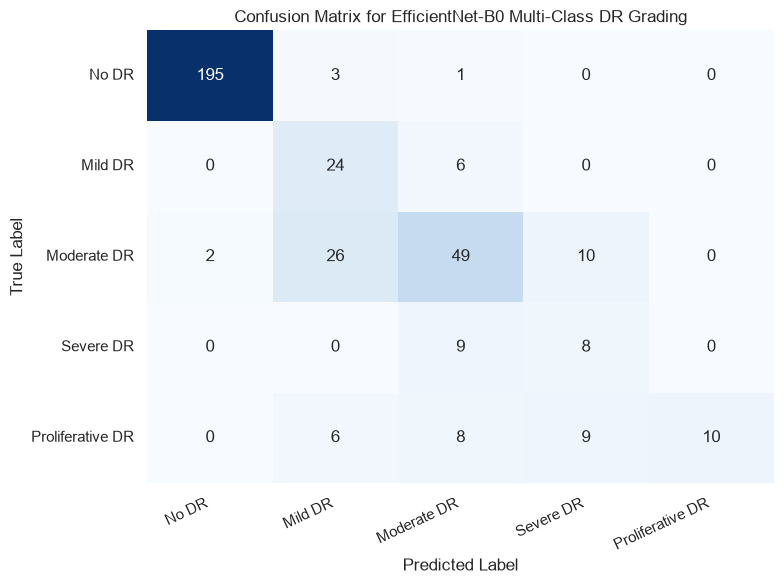

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[class_names[label] for label in class_labels],
    yticklabels=[class_names[label] for label in class_labels],
    ax=ax,
)
ax.set_title("Confusion Matrix for EfficientNet-B0 Multi-Class DR Grading")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(figures_dir / "figure_11_1_multiclass_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 11.2. Row-normalized confusion matrix for the EfficientNet-B0 multi-class DR grading experiment**


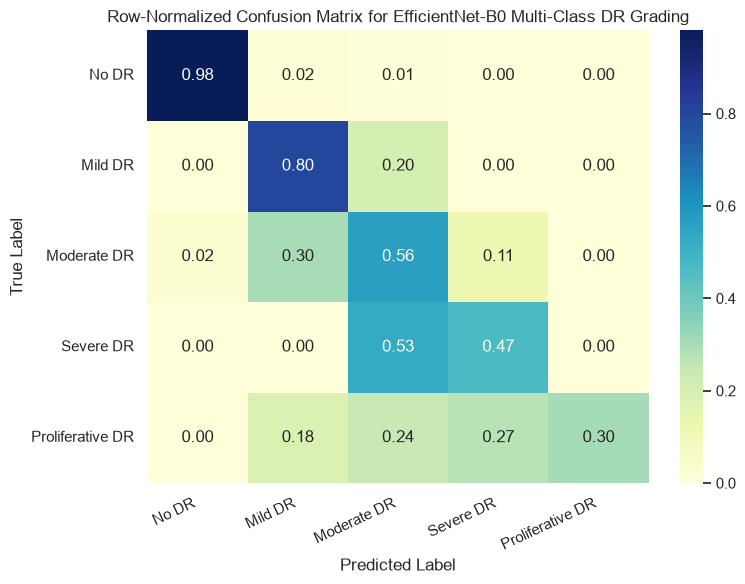

In [8]:
cm_normalized = cm.astype(np.float32) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar=True,
    xticklabels=[class_names[label] for label in class_labels],
    yticklabels=[class_names[label] for label in class_labels],
    ax=ax,
)
ax.set_title("Row-Normalized Confusion Matrix for EfficientNet-B0 Multi-Class DR Grading")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(figures_dir / "figure_11_2_multiclass_confusion_matrix_normalized.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 11.3. Per-class precision, recall, and F1-score for the EfficientNet-B0 multi-class DR grading experiment**


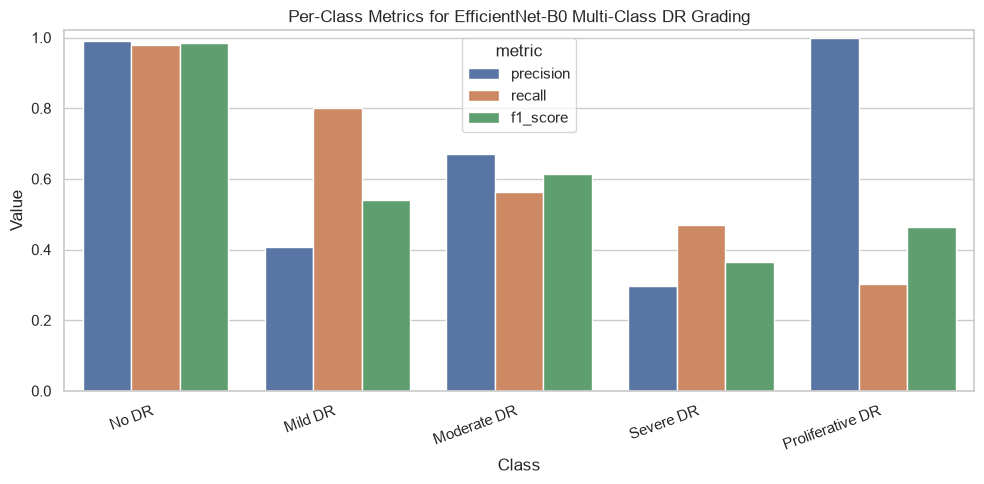

In [9]:
plot_df = per_class_metrics_df.melt(
    id_vars=["class_id", "class_name", "support"],
    value_vars=["precision", "recall", "f1_score"],
    var_name="metric",
    value_name="value",
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="class_name", y="value", hue="metric", ax=ax)
ax.set_title("Per-Class Metrics for EfficientNet-B0 Multi-Class DR Grading")
ax.set_xlabel("Class")
ax.set_ylabel("Value")
ax.set_ylim(0, 1.02)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
fig.savefig(figures_dir / "figure_11_3_multiclass_per_class_metrics.png", dpi=300, bbox_inches="tight")
plt.show()
